# 04 — Transfer learning with ResNet50

**Q3 (part). Does starting from a pretrained network beat learning from scratch?**

ResNet50 pretrained on ImageNet, fine-tuned on split v2 (`src/models/transfer.py`). Everything else matches the simple CNN in notebook 03, so pretraining is the main change:

- **Head:** the ImageNet classifier is replaced by dropout 0.3 → linear layer to the 9 classes. 23.5M parameters in total.
- **Input:** 128×128 RGB (same as the simple CNN), normalised with ImageNet mean/std, which the backbone was trained with.
- **Two-stage training:** 2 epochs training only the new head (lr 1e-3, backbone frozen), then the whole network (Adam lr 1e-4, weight decay 1e-4, cosine decay), 15 epochs in total, batch size 32. No augmentation or class weighting.
- **Model selection:** best validation macro F1; early stopping after 5 epochs without improvement.

This notebook reads the saved results. To re-train:

```bash
python -m src.train --config experiments/configs/resnet50.yaml
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

ROOT = Path('..')
METRICS = ROOT / 'results' / 'metrics'
CM_DIR = ROOT / 'results' / 'confusion_matrices'
FIG_DIR = ROOT / 'results' / 'figures'
sns.set_theme(style='whitegrid')

KEYS = ['macro_f1', 'macro_precision', 'macro_recall', 'accuracy']


def load(run):
    return json.loads((METRICS / f'{run}.json').read_text())


def scores(runs, who='model'):
    """One row per run: val and test metrics from the saved results JSON."""
    rows = {}
    for name, r in runs.items():
        rows[name] = {f'{split} {k}': r['splits'][split][who][k]
                      for split in ('val', 'test') for k in KEYS}
    return pd.DataFrame(rows).T.round(3)


def per_class_f1(runs, split='test'):
    return pd.DataFrame({name: {c: m['f1'] for c, m in r['splits'][split]['model']['per_class'].items()}
                         for name, r in runs.items()}).round(3)

In [2]:
resnet = load('resnet50')
cnn = load('simple_cnn')
knn = load('knn_hist')
runs = {'KNN colour histogram': knn, 'Simple CNN': cnn, 'ResNet50': resnet}
table = scores(runs)
table['parameters'] = ['–', f"{cnn['n_params']:,}", f"{resnet['n_params']:,}"]
table['best epoch'] = ['–', cnn['best_epoch'], resnet['best_epoch']]
table

,val macro_f1,val macro_precision,val macro_recall,val accuracy,test macro_f1,test macro_precision,test macro_recall,test accuracy,parameters,best epoch
KNN colour histogram,0.406,0.442,0.394,0.524,0.452,0.493,0.437,0.581,–,–
Simple CNN,0.649,0.654,0.671,0.708,0.735,0.748,0.747,0.790,"1,175,529",28
ResNet50,0.662,0.678,0.664,0.707,0.726,0.728,0.737,0.772,"23,526,473",11


## 1. Training curves: ResNet50 vs simple CNN

Simple CNN: train accuracy first >= 0.95 at epoch 24; best val macro F1 0.649 at epoch 28
ResNet50: train accuracy first >= 0.95 at epoch 5; best val macro F1 0.662 at epoch 11


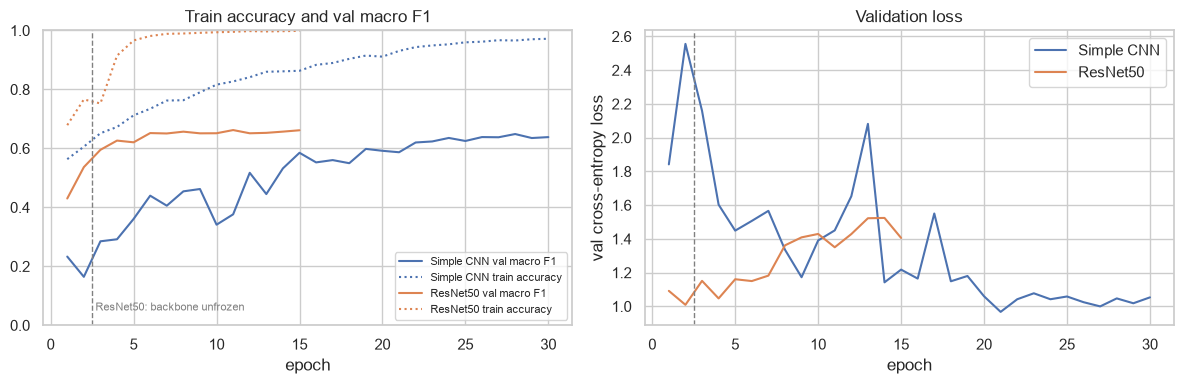

In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
for name, r in (('Simple CNN', cnn), ('ResNet50', resnet)):
    h = pd.DataFrame(r['history'])
    line, = a.plot(h.epoch, h.val_macro_f1, label=f'{name} val macro F1')
    a.plot(h.epoch, h.train_acc, color=line.get_color(), ls=':', label=f'{name} train accuracy')
    b.plot(h.epoch, h.val_loss, label=name)
freeze = resnet['config']['training']['freeze_epochs']
for ax in (a, b):
    ax.axvline(freeze + 0.5, color='grey', ls='--', lw=1)
a.text(freeze + 0.7, 0.05, 'ResNet50: backbone unfrozen', color='grey', fontsize=8)
a.set_xlabel('epoch'); a.set_ylim(0, 1); a.legend(fontsize=8); a.set_title('Train accuracy and val macro F1')
b.set_xlabel('epoch'); b.set_ylabel('val cross-entropy loss'); b.legend(); b.set_title('Validation loss')
fig.tight_layout(); fig.savefig(FIG_DIR / 'transfer_vs_cnn_curves.png', dpi=150)

for name, r in (('Simple CNN', cnn), ('ResNet50', resnet)):
    h = pd.DataFrame(r['history']).set_index('epoch')
    first = h.index[h.train_acc >= 0.95].min()
    print(f"{name}: train accuracy first >= 0.95 at epoch {first}; best val macro F1 {h.val_macro_f1.max():.3f} at epoch {r['best_epoch']}")

## 2. Per-class test F1

,KNN colour histogram,Simple CNN,ResNet50
Chinee apple,0.228,0.631,0.601
Lantana,0.517,0.779,0.782
Parkinsonia,0.525,0.820,0.812
Parthenium,0.211,0.549,0.406
Prickly acacia,0.614,0.701,0.763
Rubber vine,0.344,0.765,0.776
Siam weed,0.588,0.901,0.893
Snake weed,0.319,0.608,0.665
Negative,0.726,0.860,0.833


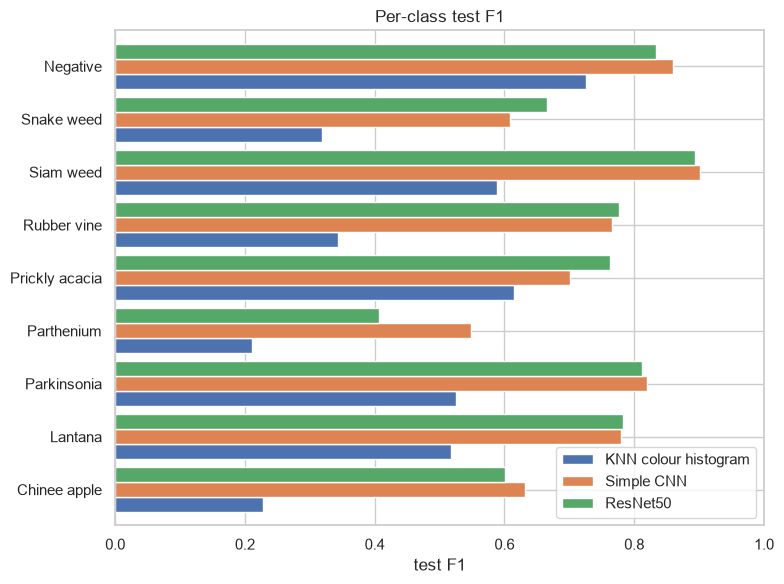

In [4]:
f1 = per_class_f1(runs)
ax = f1.plot.barh(figsize=(8, 6), width=0.85)
ax.set_xlabel('test F1'); ax.set_xlim(0, 1); ax.set_title('Per-class test F1')
ax.figure.tight_layout(); ax.figure.savefig(FIG_DIR / 'transfer_per_class_f1.png', dpi=150)
f1

## 3. Confusion matrix (test, row-normalised)

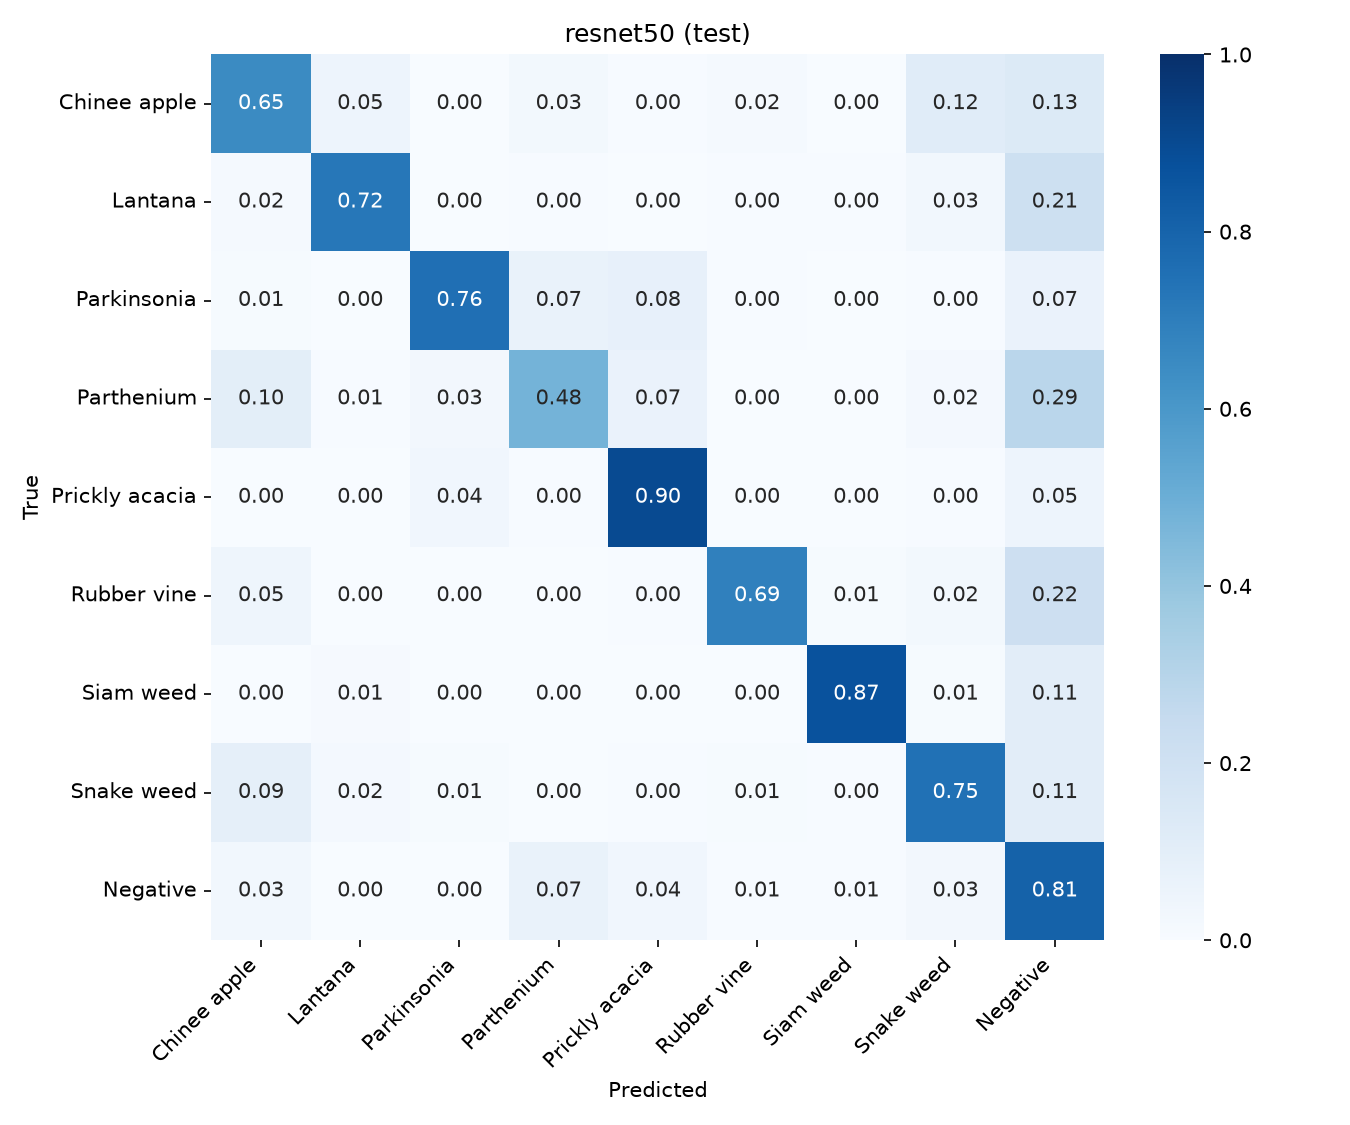

Negative -> Parthenium: 130
Negative -> Prickly acacia: 66
Negative -> Chinee apple: 62
Negative -> Snake weed: 56
Parthenium -> Negative: 50


In [5]:
display(Image(CM_DIR / 'resnet50_test.png', width=600))
for t, p, n in resnet['top_confusions_test']:
    print(f'{t} -> {p}: {n}')

## Takeaways

- **Pretraining didn't beat the simple CNN here.** ResNet50 scores test macro F1 0.726 against 0.735, and validation 0.662 against 0.649. With one run each, the two are level, even though ResNet50 has 20× the parameters.
- **It learns much faster.** Training accuracy passes 95% at epoch 5 (epoch 24 for the simple CNN), and its best checkpoint is at epoch 11 rather than 28.
- **It memorises the training set quickly.** Training accuracy reaches 99%, while validation loss rises from about 1.0 at epoch 2 to about 1.5 and validation macro F1 stays flat around 0.65. Fine-tuning all 23.5M parameters on 10.5k images without augmentation overfits.
- **The two make different mistakes.** ResNet50 is better on Prickly acacia (+0.06) and Snake weed (+0.06), but much worse on Parthenium (0.406 against 0.549), with 130 *Negative* images predicted as Parthenium.
- **Likely limits:** 128×128 input is about half the resolution ResNet50 was pretrained at, and there is no augmentation. These are the next experiments.